# Umbral de baja confianza

**Grupo G7 · José · oct/2026**

Cuando el modelo reparte sus probabilidades entre varias clases, su predicción es menos fiable. Este notebook calcula a partir de qué **probabilidad máxima** conviene aceptar una predicción y cuándo es mejor marcarla como *baja confianza* para que una persona la revise (contrato técnico, sección 7).

Procedimiento:

1. Se arma la **MLP final** (MLP+GA, semilla 42), sin reentrenarla ni guardarla.
2. Con la validación cruzada por grupos del proyecto se obtienen **probabilidades fuera de pliegue** de los 1.827 ciclos de entrenamiento: cada ciclo recibe su probabilidad de un modelo que no lo vio.
3. Para cada umbral se mide la **exactitud** de las predicciones aceptadas (probabilidad máxima ≥ umbral) y la **cobertura** (porcentaje de ciclos aceptados).
4. Se elige el umbral **más bajo** con exactitud ≥ 90 %. Si ninguno lo lograra, se usaría el de mejor relación entre exactitud y cobertura (media armónica).

**Solo se usa entrenamiento.** El conjunto de prueba no se carga ni se consulta.

In [1]:
import ast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier

from ic_g7 import config
from ic_g7.confianza import (
    OBJETIVO_EXACTITUD, elegir_umbral, probabilidades_fuera_de_pliegue, tabla_umbrales,
)
from ic_g7.datos import cargar_entrenamiento
from ic_g7.evaluacion import crear_cv
from ic_g7.pipeline import crear_pipeline

X, y, grupos = cargar_entrenamiento()
PLIEGUES = list(crear_cv().split(X, y, grupos))
print(f"Entrenamiento: {len(X)} ciclos, {X.shape[1]} variables, {grupos.nunique()} grupos")

Entrenamiento: 1827 ciclos, 68 variables, 111 grupos


## 1. El modelo final

Los hiperparámetros se leen de la fila *MLP+GA (semilla 42)* de `reports/resultados_jose.csv` (solo lectura) y se comparan con los valores decididos para el modelo final.

In [2]:
resultados = pd.read_csv(config.DIR_REPORTES / "resultados_jose.csv")
fila = resultados.loc[resultados["modelo"] == "MLP+GA (semilla 42)"].iloc[0]
HIPERPARAMETROS = ast.literal_eval(fila["hiperparámetros"])

esperados = {
    "hidden_layer_sizes": (64,),
    "alpha": 0.0035127047262708444,
    "learning_rate_init": 0.0026698666742744587,
    "activation": "tanh",
    "max_iter": 4000,
    "random_state": config.RANDOM_STATE,
}
assert HIPERPARAMETROS == esperados, HIPERPARAMETROS
print("Hiperparámetros del CSV = hiperparámetros decididos")
print("F1 macro CV del modelo:", fila["F1_macro_CV (media±std)"])

modelo = crear_pipeline(MLPClassifier(**HIPERPARAMETROS))

Hiperparámetros del CSV = hiperparámetros decididos
F1 macro CV del modelo: 0.8123 ± 0.0543


## 2. Probabilidades fuera de pliegue

`probabilidades_fuera_de_pliegue` (que usa `cross_val_predict`) ajusta el pipeline completo (escalado, filtro de correlación y MLP) con cuatro pliegues y predice el quinto, usando los mismos cinco pliegues por grupos del proyecto. Así ningún ciclo se predice con un modelo que haya visto su combinación de componentes. Las columnas de la salida siguen el orden de las clases 0 a 3 (90, 100, 115 y 130 bar). Si aparece un aviso de convergencia de la MLP, la función lanza un error y no se calibra nada.

In [3]:
P = probabilidades_fuera_de_pliegue(modelo, X, y, grupos, PLIEGUES)
y_real = y.to_numpy()
prediccion = P.argmax(axis=1)
confianza = P.max(axis=1)
acierto = prediccion == y_real

print(f"Exactitud global fuera de pliegue (todos los ciclos): {acierto.mean():.4f}")
print(f"Probabilidad máxima: mediana {np.median(confianza):.3f}, mínima {confianza.min():.3f}")
assert np.allclose(P.sum(axis=1), 1)

Exactitud global fuera de pliegue (todos los ciclos): 0.8287
Probabilidad máxima: mediana 0.949, mínima 0.343


## 3. Umbral frente a exactitud y cobertura

Se recorre la rejilla de 0,25 a 0,99 de centésima en centésima (con 4 clases, 0,25 es el azar y aceptar todo). Un umbral más alto acepta menos ciclos, pero los aceptados suelen acertar más.

In [4]:
tabla = tabla_umbrales(P, y_real)
UMBRAL, ALCANZADO, CRITERIO = elegir_umbral(tabla, OBJETIVO_EXACTITUD)

mostrar = [0.25, 0.50, 0.60, 0.70, 0.80, 0.85, 0.86, 0.87, 0.88, 0.90, 0.95]
resumen = tabla[tabla["umbral"].round(2).isin(mostrar)].copy()
resumen["cobertura (%)"] = (resumen["cobertura"] * 100).round(1)
resumen["exactitud (%)"] = (resumen["exactitud"] * 100).round(1)
resumen["rechazados"] = len(y_real) - resumen["aceptados"]
display(resumen[["umbral", "aceptados", "rechazados", "cobertura (%)", "exactitud (%)"]]
        .reset_index(drop=True))
print(f"Objetivo de exactitud: {OBJETIVO_EXACTITUD:.0%} · alcanzado: {ALCANZADO}")
print(f"Criterio: {CRITERIO}")
print(f"Umbral elegido: {UMBRAL:.2f}")

,umbral,aceptados,rechazados,cobertura (%),exactitud (%)
0,0.25,1827,0,100.0,82.9
1,0.50,1796,31,98.3,83.6
2,0.60,1695,132,92.8,85.0
3,0.70,1557,270,85.2,86.4
4,0.80,1379,448,75.5,88.4
5,0.85,1260,567,69.0,89.7
6,0.86,1229,598,67.3,90.0
7,0.87,1206,621,66.0,90.1
8,0.88,1177,650,64.4,90.2
9,0.90,1124,703,61.5,90.6


Objetivo de exactitud: 90% · alcanzado: True
Criterio: umbral mas bajo con exactitud >= objetivo
Umbral elegido: 0.87


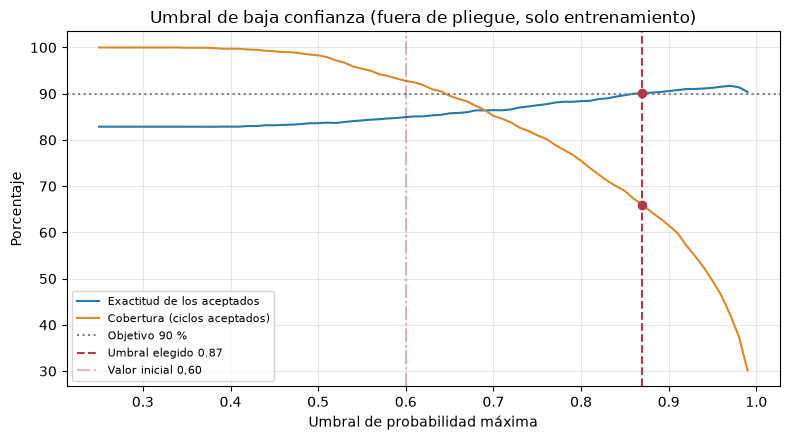

In [5]:
elegida = tabla.loc[np.isclose(tabla["umbral"], UMBRAL)].iloc[0]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tabla["umbral"], tabla["exactitud"] * 100, color="#2878a8", label="Exactitud de los aceptados")
ax.plot(tabla["umbral"], tabla["cobertura"] * 100, color="#d98a2b", label="Cobertura (ciclos aceptados)")
ax.axhline(OBJETIVO_EXACTITUD * 100, color="gray", linestyle=":", label="Objetivo 90 %")
ax.axvline(UMBRAL, color="#b03a48", linestyle="--", label=f"Umbral elegido {UMBRAL:.2f}")
ax.axvline(0.60, color="#b03a48", alpha=0.35, linestyle="-.", label="Valor inicial 0,60")
ax.scatter([UMBRAL, UMBRAL], [elegida["exactitud"] * 100, elegida["cobertura"] * 100],
           color="#b03a48", zorder=3)
ax.set(xlabel="Umbral de probabilidad máxima", ylabel="Porcentaje",
       title="Umbral de baja confianza (fuera de pliegue, solo entrenamiento)")
ax.grid(alpha=0.3)
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(config.DIR_REPORTES / "figuras" / "umbral_confianza_jose.png", dpi=150)
plt.show()

## 4. ¿Qué tan firme es ese umbral?

El umbral sale de una sola tabla, así que conviene ver cuánto cambia el resultado. Tres comprobaciones, siempre con las mismas predicciones fuera de pliegue:

- **Por pliegue**: exactitud y cobertura en cada uno de los cinco pliegues. Los tres grupos grandes dominan cada uno un pliegue, por eso se espera variación.
- **Remuestreo por grupos**: 2.000 remuestreos con reemplazo de los grupos completos (no de ciclos sueltos, que están muy correlacionados), semilla del proyecto.
- **Por clase**: qué clases quedan sin aceptar.

In [6]:
aceptados = confianza >= UMBRAL
filas = []
for numero, (_, validacion) in enumerate(PLIEGUES):
    a = aceptados[validacion]
    filas.append({
        "pliegue": numero, "ciclos": len(validacion),
        "cobertura (%)": a.mean() * 100,
        "exactitud aceptados (%)": acierto[validacion][a].mean() * 100 if a.any() else np.nan,
        "exactitud sin umbral (%)": acierto[validacion].mean() * 100,
    })
por_pliegue = pd.DataFrame(filas)
display(por_pliegue.round(1))

rng = np.random.default_rng(config.RANDOM_STATE)
ids = grupos.to_numpy()
indices_por_grupo = {g: np.flatnonzero(ids == g) for g in np.unique(ids)}
lista = np.array(list(indices_por_grupo))
exactitudes, coberturas = [], []
for _ in range(2000):
    elegidos = rng.choice(lista, size=len(lista), replace=True)
    idx = np.concatenate([indices_por_grupo[g] for g in elegidos])
    a = aceptados[idx]
    if a.any():
        exactitudes.append(acierto[idx][a].mean())
        coberturas.append(a.mean())
ic_exa = np.percentile(exactitudes, [2.5, 97.5]) * 100
ic_cob = np.percentile(coberturas, [2.5, 97.5]) * 100
print(f"Exactitud de los aceptados: {acierto[aceptados].mean():.1%}  (IC 95 % por grupos: {ic_exa[0]:.1f} a {ic_exa[1]:.1f} %)")
print(f"Cobertura: {aceptados.mean():.1%}  (IC 95 % por grupos: {ic_cob[0]:.1f} a {ic_cob[1]:.1f} %)")
print(f"Remuestreos con exactitud >= 90 %: {np.mean(np.array(exactitudes) >= 0.90):.1%}")

bar = {v: k for k, v in config.CLASE_POR_OBJETIVO.items()}
por_clase = pd.DataFrame({
    "ciclos": pd.Series(y_real).value_counts().sort_index(),
    "aceptados": pd.Series(y_real[aceptados]).value_counts().sort_index(),
}).fillna(0).astype(int)
por_clase["cobertura (%)"] = (por_clase["aceptados"] / por_clase["ciclos"] * 100).round(1)
por_clase["exactitud aceptados (%)"] = [
    round(acierto[aceptados & (y_real == c)].mean() * 100, 1) for c in por_clase.index
]
por_clase.index = [f"{bar[c]} bar" for c in por_clase.index]
display(por_clase)

,pliegue,ciclos,cobertura (%),exactitud aceptados (%),exactitud sin umbral (%)
0,0,424,61.8,86.3,78.1
1,1,426,45.1,97.9,88.5
2,2,416,74.5,97.4,89.9
3,3,285,78.6,88.8,80.4
4,4,276,79.0,78.9,73.6


Exactitud de los aceptados: 90.1%  (IC 95 % por grupos: 84.5 a 94.6 %)
Cobertura: 66.0%  (IC 95 % por grupos: 60.2 a 72.8 %)
Remuestreos con exactitud >= 90 %: 54.8%


,ciclos,aceptados,cobertura (%),exactitud aceptados (%)
90 bar,686,459,66.9,91.5
100 bar,317,218,68.8,90.4
115 bar,317,163,51.4,87.7
130 bar,507,366,72.2,89.3


## 5. Decisión y límites

- **Umbral final: 0,87.** Es el más bajo (en pasos de 0,01) con el que las predicciones aceptadas aciertan al menos el 90 %: el 0,86 se queda en 89,99 %. Con 0,87 se aceptan **1.206 de 1.827 ciclos (66,0 %)** con **exactitud 90,1 %**; los otros 621 (34,0 %) se marcan como *baja confianza*. Sin umbral el modelo acierta el 82,9 %.
- **Qué cambia respecto al 0,60 inicial.** Con 0,60 se aceptaban el 92,8 % de los ciclos pero con 85,0 % de exactitud: no llegaba al 90 %. Subir el umbral intercambia cobertura por exactitud.
- **Valor guardado:** `config.UMBRAL_CONFIANZA = 0.87` (la última celda comprueba que coincide).
- **Límites, para decirlo con honestidad en el informe:**
  - El 90 % se cumple *en promedio*, pero con poco margen: el intervalo por remuestreo de grupos va de 84,5 a 94,6 % y solo en 55 % de los remuestreos se llega a 90 %. El umbral se eligió con los mismos datos en que se mide, así que es algo optimista.
  - Por pliegue la exactitud de los aceptados varía de 78,9 a 97,9 %. El pliegue 4 queda por debajo del 90 % aun con el umbral, y la clase 115 bar es la que menos se acepta (51 %) y la que menos acierta (87,7 %).
  - Las probabilidades de una MLP no están calibradas: 0,87 no significa "87 % de acierto". Es un punto de corte práctico, no una probabilidad real.
  - La evaluación única en prueba (27/oct) dirá si el umbral se mantiene con combinaciones nuevas; no se usó aquí.

In [7]:
assert config.UMBRAL_CONFIANZA == UMBRAL, (
    f"config.UMBRAL_CONFIANZA={config.UMBRAL_CONFIANZA} no coincide con el umbral calculado {UMBRAL}"
)
print(f"config.UMBRAL_CONFIANZA = {config.UMBRAL_CONFIANZA} (coincide con el calculado)")

config.UMBRAL_CONFIANZA = 0.87 (coincide con el calculado)
